# 🕵️‍♀️​ Exploration of: Cognitive Distortion detetction dataset 2

link of the website: 
https://zenodo.org/records/17365993

In [5]:
import pandas as pd
import numpy as np

import string

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [6]:


data = pd.read_json("/Users/abiboubou/code/youhsuanchang/project/CODIPAS.json")

data.head()

,Id_Patient_Question,Id_Distorted_Part,Patient Question,Distorted Part,Distortions
0,4500,1,"Hello, I have a beautiful,smart,outgoing and a...",Im very concerned about this and hope it has n...,"{'Dominant Distortion': 'Personalization', 'Se..."
1,4501,2,Since I was about 16 years old I’ve had these ...,"""I think during these times that I don’t deser...","{'Dominant Distortion': 'Should statements', '..."
2,4502,3,So I’ve been dating on and off this guy for a...,"""I still have feelings for him that’s why I al...",{'Dominant Distortion': 'All-or-nothing thinki...
3,4503,4,My parents got divorced in 2004. My mother has...,"""I blamed my mom for everything that went wrong.""","{'Dominant Distortion': 'Personalization', 'Se..."
4,4504,5,I don’t really know how to explain the situati...,"""It seems like every time I get so close of be...","{'Dominant Distortion': 'Overgeneralization', ..."


In [4]:
data.shape

(5055, 5)

In [8]:
X = data[["Patient Question"]]
X.duplicated().value_counts()

False    3276
True     1779
Name: count, dtype: int64

In [9]:
data['text_word_count'] = data["Patient Question"].fillna('').str.split().str.len()
data.head()

,Id_Patient_Question,Id_Distorted_Part,Patient Question,Distorted Part,Distortions,text_word_count
0,4500,1,"Hello, I have a beautiful,smart,outgoing and a...",Im very concerned about this and hope it has n...,"{'Dominant Distortion': 'Personalization', 'Se...",131
1,4501,2,Since I was about 16 years old I’ve had these ...,"""I think during these times that I don’t deser...","{'Dominant Distortion': 'Should statements', '...",292
2,4502,3,So I’ve been dating on and off this guy for a...,"""I still have feelings for him that’s why I al...",{'Dominant Distortion': 'All-or-nothing thinki...,447
3,4503,4,My parents got divorced in 2004. My mother has...,"""I blamed my mom for everything that went wrong.""","{'Dominant Distortion': 'Personalization', 'Se...",181
4,4504,5,I don’t really know how to explain the situati...,"""It seems like every time I get so close of be...","{'Dominant Distortion': 'Overgeneralization', ...",295


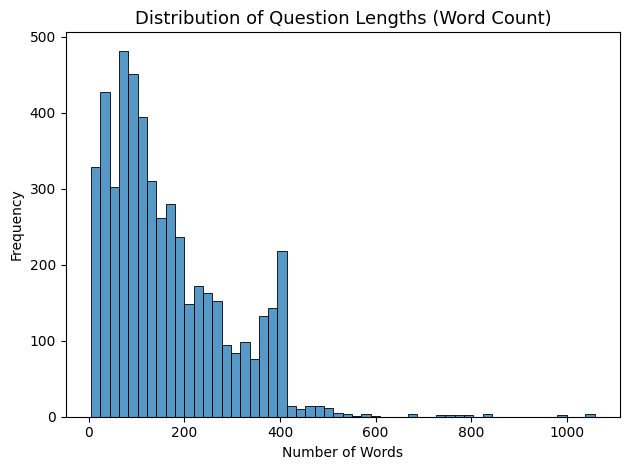

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.histplot(data=data, x='text_word_count')

plt.title('Distribution of Question Lengths (Word Count)', fontsize=13)
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [18]:

print(f"Length of the Patient Question: Mean: {round(data['text_word_count'].mean(), 2)}, Min: {min(data['text_word_count'])}, Max: {max(data['text_word_count'])}")

Length of the Patient Question: Mean: 165.48, Min: 4, Max: 1059


In [19]:
data["Distortions"].value_counts(normalize=True)

Distortions
{'Dominant Distortion': 'No distortion', 'Secondary Distortion': None}                           0.549555
{'Dominant Distortion': 'Labeling', 'Secondary Distortion': None}                                0.069238
{'Dominant Distortion': 'Should statements', 'Secondary Distortion': None}                       0.051039
{'Dominant Distortion': 'Mind reading', 'Secondary Distortion': None}                            0.047873
{'Dominant Distortion': 'Emotional reasoning', 'Secondary Distortion': None}                     0.039960
                                                                                                   ...   
{'Dominant Distortion': 'Personalization', 'Secondary Distortion': 'Mental filter'}              0.000198
{'Dominant Distortion': 'Magnification', 'Secondary Distortion': 'Mental filter'}                0.000198
{'Dominant Distortion': 'Personalization', 'Secondary Distortion': 'Emotional reasoning'}        0.000198
{'Dominant Distortion': 'Magnifica